# Predicting GitHub user activity

A temporal GNN forecasts six activities for Nov. 22 to 29, 2026 (Taiwan time). Follow [README.md](README.md) to prepare the data.

## Setup

Run from the repository root. Set `ASSIGNMENT_STUDENT_ID` or edit `STUDENT_ID` before exporting predictions.

In [1]:
import json
import os
import re
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from scipy.optimize import minimize
from scipy.special import expit
from scipy.sparse import csr_matrix
from threadpoolctl import threadpool_limits

from scripts.evaluate import EVENT_COLS, OUTPUT_COLUMNS, USER_COL, scores
from scripts.preprocess import TABLES

ROOT = Path.cwd()
DATA = ROOT / "data"
RESULTS = ROOT / "results"
TEST_INPUT = ROOT / "submission" / "test_input.csv"
STUDENT_ID = os.environ.get("ASSIGNMENT_STUDENT_ID", "315540018").strip()

TEST_START = pd.Timestamp("2026-11-22 00:00", tz="Asia/Taipei").tz_convert("UTC")
WEEK = pd.Timedelta(days=7)
WINDOWS = (1, 3, 7, 10)
MIN_HISTORY = pd.Timedelta(days=max(WINDOWS))
MIN_COVERAGE = 0.90
N_THREADS = 4

if STUDENT_ID and re.fullmatch(r"[0-9]+", STUDENT_ID) is None:
    raise ValueError("STUDENT_ID must contain digits only.")

required = [DATA / "hours.json", *(DATA / "db" / f"{table}.parquet" for table in TABLES)]
missing = [path.relative_to(ROOT).as_posix() for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError("Run the README data preparation steps first. Missing: " + ", ".join(missing))

RESULTS.mkdir(exist_ok=True)

## Chronological split

Use the same cutoff-to-target gap as the official forecast. Fit on earlier weeks, tune thresholds on the penultimate week, and evaluate on the latest complete week. The coverage check counts available hourly files.

In [2]:
manifest = json.loads((DATA / "hours.json").read_text(encoding="utf-8"))
archive_start = pd.Timestamp(manifest["start_utc"])
archive_end = pd.Timestamp(manifest["end_utc_exclusive"])
present_hours = pd.DatetimeIndex(pd.to_datetime(manifest["present_utc"], utc=True)).unique()
deadline = pd.Timestamp("2026-11-21 23:55", tz="Asia/Taipei").tz_convert("UTC")
if not archive_start < archive_end <= deadline or manifest["failed_utc"]:
    raise ValueError("Use a completed historical archive download that ends before the deadline.")
if present_hours.empty or present_hours.min() < archive_start or present_hours.max() >= archive_end:
    raise ValueError("Archive coverage falls outside the interval in hours.json.")

forecast_gap = TEST_START - archive_end

def archive_coverage(start, end):
    observed = ((present_hours >= start) & (present_hours < end)).sum()
    return observed / ((end - start) / pd.Timedelta(hours=1))


def previous_complete_fold(target_end):
    """Find an earlier full label week within the downloaded history."""
    while target_end - WEEK - forecast_gap - MIN_HISTORY >= archive_start:
        target_start = target_end - WEEK
        cutoff = target_start - forecast_gap
        label_coverage = archive_coverage(target_start, target_end)
        history_coverage = archive_coverage(cutoff - MIN_HISTORY, cutoff)
        if target_end <= archive_end and min(label_coverage, history_coverage) >= MIN_COVERAGE:
            return {
                "cutoff": cutoff,
                "target_start": target_start,
                "target_end": target_end,
                "label_hour_coverage": label_coverage,
            }
        target_end -= WEEK
    return None


held_out_fold = previous_complete_fold(TEST_START)
tune_fold = previous_complete_fold(held_out_fold["cutoff"]) if held_out_fold else None
train_folds = []
earlier = previous_complete_fold(tune_fold["cutoff"]) if tune_fold else None
while earlier is not None:
    train_folds.append(earlier)
    earlier = previous_complete_fold(earlier["target_start"])

if not train_folds:
    raise ValueError("Need enough history for separate training, tuning, and held-out weeks. Extend the archive start.")
folds = pd.DataFrame([
    *(dict(fold, split="train") for fold in reversed(train_folds)),
    dict(tune_fold, split="tune"),
    dict(held_out_fold, split="held out"),
])
for split in ("tune", "held out"):
    cutoff = folds.loc[folds["split"].eq(split), "cutoff"].iloc[0]
    if folds.loc[folds["cutoff"].lt(cutoff), "target_end"].gt(cutoff).any():
        raise ValueError(f"Earlier labels overlap the {split} feature cutoff.")

print(f"GH Archive (UTC): {archive_start:%Y-%m-%d %H:%M} to {archive_end:%Y-%m-%d %H:%M} (exclusive)")
print(f"Hours available: {len(present_hours):,}  |  Feature-to-target gap: {forecast_gap}")
display(folds)

GH Archive (UTC): 2026-10-03 16:00 to 2026-11-20 15:00 (exclusive)
Hours available: 1,151  |  Feature-to-target gap: 1 days 01:00:00


,cutoff,target_start,target_end,label_hour_coverage,split
0,2026-10-14 13:00:00+00:00,2026-10-15 14:00:00+00:00,2026-10-22 14:00:00+00:00,1.0,train
1,2026-10-21 13:00:00+00:00,2026-10-22 14:00:00+00:00,2026-10-29 14:00:00+00:00,1.0,train
2,2026-10-29 14:00:00+00:00,2026-10-30 15:00:00+00:00,2026-11-06 15:00:00+00:00,1.0,tune
3,2026-11-06 15:00:00+00:00,2026-11-07 16:00:00+00:00,2026-11-14 16:00:00+00:00,1.0,held out


### Course tables

Join on the preprocessor's row IDs and export anonymized GitHub user IDs. Keep cohort users with no observed activity in the training data.

In [3]:
columns = {
    "Users": ["user_id", "github_user_id", "is_cohort", "first_seen_at"],
    "Repositories": ["repo_id", "first_seen_at"],
    "PullRequests": ["pr_id", "author_id", "repo_id", "first_seen_at", "created_at"],
    "Issues": ["issue_id", "author_id", "repo_id", "first_seen_at", "created_at", "is_pull_request"],
    "IssueComments": ["issue_id", "author_id", "repo_id", "created_at", "is_pull_request"],
    "PRReviews": ["pr_id", "reviewer_id", "repo_id", "first_seen_at", "submitted_at"],
    "PRReviewComments": ["pr_id", "author_id", "repo_id", "created_at"],
    "Pushes": ["user_id", "repo_id", "created_at"],
}
tables = {}
for name, fields in columns.items():
    foreign_keys = [key for key in TABLES[name]['fks'] if key != 'merged_by_id']
    fields = list(dict.fromkeys([*fields, TABLES[name]['pk'], *foreign_keys]))
    table = pd.read_parquet(DATA / "db" / f"{name}.parquet", columns=fields)
    for field in {"first_seen_at", "created_at", "submitted_at"}.intersection(fields):
        table[field] = pd.to_datetime(table[field], utc=True)
    tables[name] = table

test_users = pd.Index(pd.read_csv(TEST_INPUT, dtype={USER_COL: "int64"})[USER_COL], name=USER_COL)
cohort = pd.Index(
    sorted({int(line) for line in (ROOT / "scripts" / "cohort.txt").read_text().split()}),
    name=USER_COL,
)
if test_users.has_duplicates or not test_users.isin(cohort).all():
    raise ValueError("Expected unique test IDs from the course cohort.")
observed_cohort = tables["Users"].loc[tables["Users"]["is_cohort"], "github_user_id"]
if not observed_cohort.isin(cohort).all():
    raise ValueError("The preprocessed user table does not match the supplied course cohort.")

display(pd.Series({name: len(table) for name, table in tables.items()}, name="Rows").to_frame())
print(f"Cohort: {len(cohort):,} users  |  Official test list: {len(test_users):,} users")

Cohort: 9,000 users  |  Official test list: 4,465 users


,Rows
Users,5680
Repositories,11773
PullRequests,13379
Issues,8489
IssueComments,3206
PRReviews,3301
PRReviewComments,1423
Pushes,35276


### Events and target labels

Use row time for feature availability. A positive label also requires the action to fall in the target week, so an old issue first seen through a new comment does not count as a new opening.

In [4]:
activity_specs = {
    "open_pr": ("PullRequests", "author_id", "first_seen_at", "created_at"),
    "open_issue": ("Issues", "author_id", "first_seen_at", "created_at"),
    "issue_comment": ("IssueComments", "author_id", "created_at", "created_at"),
    "pr_review": ("PRReviews", "reviewer_id", "first_seen_at", "submitted_at"),
    "pr_review_comment": ("PRReviewComments", "author_id", "created_at", "created_at"),
    "push": ("Pushes", "user_id", "created_at", "created_at"),
}
users_by_key = tables["Users"].set_index("user_id")
user_codes = users_by_key["github_user_id"]
user_times = users_by_key["first_seen_at"]

def build_activity():
    blocks = []
    for activity, (table_name, actor, row_time, action_time) in activity_specs.items():
        source = tables[table_name]
        if activity == "open_issue":
            source = source.loc[source["is_pull_request"].eq(False)]
        block = pd.DataFrame({
            USER_COL: source[actor].map(user_codes),
            "repo_id": source["repo_id"],
            "row_at": source[row_time],
            "action_at": source[action_time],
            "user_seen_at": source[actor].map(user_times),
            "activity": activity,
        })
        blocks.append(block.loc[block[USER_COL].isin(cohort)].dropna(subset=["row_at"]))
    events = pd.concat(blocks, ignore_index=True)
    events[USER_COL] = events[USER_COL].astype("int64")
    events["activity"] = pd.Categorical(events["activity"], categories=EVENT_COLS)
    events["known_at"] = events["row_at"].where(
        events["row_at"].ge(events["user_seen_at"]), events["user_seen_at"]
    )
    return events


def weekly_targets(start, end, user_index):
    observed = activity.loc[
        activity["row_at"].ge(start) & activity["known_at"].lt(end)
        & activity["action_at"].ge(start) & activity["action_at"].lt(end)
    ]
    return activity_counts(observed, user_index).gt(0).astype("int8")


def activity_counts(events, user_index):
    counts = events.groupby([USER_COL, "activity"], observed=True).size().unstack(fill_value=0)
    return counts.reindex(index=user_index, columns=EVENT_COLS, fill_value=0)


activity = build_activity()
display(activity["activity"].value_counts(sort=False).rename("Observed rows").to_frame())

,Observed rows
activity,
open_pr,4295
open_issue,5402
issue_comment,3206
pr_review,3241
pr_review_comment,1423
push,35276


## User features

- **7-day counts** Count each activity during the previous week.
- **Temporal** Add 1-, 3-, and 10-day counts, active days, recency, and changes in activity rate.
- **Temporal + relational** Add shared-repository features and feedback counts from issue and PR joins.

In [5]:
def lookback(events, cutoff, days):
    start = max(cutoff - pd.Timedelta(days=days), archive_start)
    return events.loc[events["row_at"].ge(start) & events["known_at"].lt(cutoff)]


def temporal_features(cutoff, user_index):
    recent = lookback(activity, cutoff, max(WINDOWS))
    blocks = []
    counts_by_window = {}
    for days in WINDOWS:
        window = lookback(recent, cutoff, days)
        counts = activity_counts(window, user_index)
        counts_by_window[days] = counts
        blocks.append(counts.add_prefix(f"count_{days}d_"))

    last_event = recent.groupby([USER_COL, "activity"], observed=True)["row_at"].max().unstack()
    last_event = last_event.reindex(index=user_index, columns=EVENT_COLS)
    recency = last_event.apply(lambda times: (cutoff - pd.to_datetime(times, utc=True)).dt.total_seconds() / 86400)
    recency = recency.fillna(max(WINDOWS) + 1)
    recent_days = (
        recent.assign(day=recent["row_at"].dt.floor("D"))
        .groupby([USER_COL, "activity"], observed=True)["day"].nunique().unstack(fill_value=0)
        .reindex(index=user_index, columns=EVENT_COLS, fill_value=0)
    )
    earlier_four_days = counts_by_window[7] - counts_by_window[3]
    momentum = np.log1p(counts_by_window[3] / 3) - np.log1p(earlier_four_days / 4)
    combined = pd.concat([
        *blocks,
        recency.add_prefix("recency_days_"),
        recent_days.add_prefix("active_days_10d_"),
        momentum.add_prefix("recent_rate_change_"),
    ], axis=1)
    combined["any_activity_days_10d"] = (
        recent.assign(day=recent["row_at"].dt.floor("D"))
        .groupby(USER_COL)["day"].nunique().reindex(user_index, fill_value=0)
    )
    return combined.astype("float32")

In [6]:
def received_activity(table_name, key, object_table, actor, time_field):
    """Join each comment or review to the author of the referenced issue or PR."""
    source = tables[table_name][[key, actor, time_field]].rename(
        columns={actor: "actor_id", time_field: "row_at"}
    )
    objects = tables[object_table][[key, "author_id", "first_seen_at"]].rename(
        columns={"first_seen_at": "object_seen_at"}
    )
    links = source.dropna(subset=[key, "actor_id", "row_at"]).merge(
        objects.dropna(subset=["author_id"]), on=key, validate="many_to_one"
    )
    links[USER_COL] = links["author_id"].map(user_codes)
    links = links.loc[links[USER_COL].isin(cohort) & links["actor_id"].ne(links["author_id"])].copy()
    links["known_at"] = pd.concat([
        links["row_at"],
        links["object_seen_at"],
        links["actor_id"].map(user_times),
        links["author_id"].map(user_times),
    ], axis=1).max(axis=1)
    return links[[USER_COL, "actor_id", "row_at", "known_at"]]


repository_times = tables["Repositories"].set_index("repo_id")["first_seen_at"]
activity["repo_seen_at"] = activity["repo_id"].map(repository_times)
received = {
    "issue_comment": received_activity("IssueComments", "issue_id", "Issues", "author_id", "created_at"),
    "pr_review": received_activity("PRReviews", "pr_id", "PullRequests", "reviewer_id", "first_seen_at"),
    "pr_review_comment": received_activity(
        "PRReviewComments", "pr_id", "PullRequests", "author_id", "created_at"
    ),
}


def relational_features(cutoff, user_index):
    features = pd.DataFrame(index=user_index)
    for days in (7, 10):
        recent = lookback(activity, cutoff, days)
        recent = recent.loc[recent["repo_seen_at"].lt(cutoff)]
        by_user_repo = recent.groupby([USER_COL, "repo_id"]).size().rename("own_events")
        repo_totals = by_user_repo.groupby(level="repo_id").agg(["sum", "size"])
        context = by_user_repo.to_frame().join(repo_totals, on="repo_id")
        context["peer_events"] = context["sum"] - context["own_events"]
        context["peer_users"] = context["size"] - 1
        context["shared"] = context["peer_users"].gt(0)
        by_user = context.groupby(level=USER_COL)
        aggregated = by_user.agg(
            repos=("own_events", "size"),
            shared_repos=("shared", "sum"),
            max_repo_peer_events=("peer_events", "max"),
            max_repo_peer_users=("peer_users", "max"),
            dominant_repo_events=("own_events", "max"),
            repo_events=("own_events", "sum"),
        )
        aggregated["dominant_repo_share"] = aggregated.pop("dominant_repo_events") / aggregated.pop("repo_events")
        for name in aggregated:
            features[f"{name}_{days}d"] = aggregated[name]

        for name, links in received.items():
            contact = lookback(links, cutoff, days).groupby(USER_COL)
            features[f"received_{name}_{days}d"] = contact.size()
            features[f"received_{name}_unique_people_{days}d"] = contact["actor_id"].nunique()
    return features.fillna(0).astype("float32")


def snapshot(cutoff, user_index):
    temporal = temporal_features(cutoff, user_index)
    features = temporal.join(relational_features(cutoff, user_index))
    return features

### Historical snapshots and labels

In [7]:
feature_weeks = []
label_weeks = []
for fold in folds.itertuples():
    feature_weeks.append(snapshot(fold.cutoff, cohort))
    label_weeks.append(weekly_targets(fold.target_start, fold.target_end, cohort))

labels_by_week = pd.DataFrame([labels.sum() for labels in label_weeks])
labels_by_week.index = pd.Index(folds["target_start"], name="Target start (UTC)")
display(labels_by_week)
unsupported_training = labels_by_week.loc[folds.loc[folds['split'].eq('train'), 'target_start']].sum().eq(0)
if unsupported_training.any():
    print('No training positives for ' + ', '.join(unsupported_training.index[unsupported_training]) + '.')
print(f"{len(feature_weeks[0].columns)} features across the temporal and relational blocks.")

65 features across the temporal and relational blocks.


activity,open_pr,open_issue,issue_comment,pr_review,pr_review_comment,push
Target start (UTC),,,,,,
2026-10-15 14:00:00+00:00,394,249,228,258,197,1765
2026-10-22 14:00:00+00:00,308,177,210,202,99,1134
2026-10-30 15:00:00+00:00,383,198,258,276,109,283
2026-11-07 16:00:00+00:00,338,182,205,233,69,277


## Tabular baselines

Fit L2-regularized logistic regression and choose decision thresholds on the tuning fold.

In [8]:
def log_features(features):
    values = features.to_numpy(dtype="float64")
    return np.sign(values) * np.log1p(np.abs(values))


def add_intercept(values, center, scale):
    return np.column_stack([np.ones(len(values)), (values - center) / scale])


def logistic_objective(coefficients, design, target, penalty):
    logits = design @ coefficients
    slopes = coefficients[1:]
    loss = np.mean(np.logaddexp(0, logits) - target * logits) + 0.5 * penalty * (slopes @ slopes)
    gradient = design.T @ (expit(logits) - target) / len(target)
    gradient[1:] += penalty * slopes
    return loss, gradient


def fit_models(features, labels):
    if not features.index.equals(labels.index):
        raise ValueError("Training features and labels must have the same index.")
    values = log_features(features)
    center = values.mean(axis=0)
    scale = np.maximum(values.std(axis=0), 0.1)
    design = add_intercept(values, center, scale)
    coefficients = {}
    with threadpool_limits(limits=N_THREADS):
        for event in EVENT_COLS:
            target = labels[event].to_numpy(dtype="float64")
            rate = target.mean()
            if rate in (0, 1):
                coefficients[event] = float(rate)
                continue
            initial = np.zeros(design.shape[1])
            initial[0] = np.log(rate / (1 - rate))
            fit = minimize(
                logistic_objective, initial, args=(design, target, 0.005),
                method="L-BFGS-B", jac=True, options={"maxiter": 250, "gtol": 1e-7},
            )
            if not fit.success:
                raise RuntimeError(f"Logistic fit failed for {event}: {fit.message}")
            coefficients[event] = fit.x
    return center, scale, coefficients


def predict_probabilities(models, features):
    center, scale, coefficients = models
    design = add_intercept(log_features(features), center, scale)
    probabilities = {}
    with threadpool_limits(limits=N_THREADS):
        for event, weights in coefficients.items():
            probabilities[event] = weights if isinstance(weights, float) else expit(design @ weights)
    return pd.DataFrame(probabilities, index=features.index)


def tune_thresholds(probabilities, labels):
    """Coordinate search using the course macro/micro score and observed probability ranks."""
    y = labels[EVENT_COLS].to_numpy(dtype=bool)
    p = probabilities[EVENT_COLS].to_numpy()
    ranks = np.r_[np.linspace(0, 0.9, 41), np.linspace(0.901, 1, 100)]
    candidates = [
        np.unique(np.r_[np.quantile(column, ranks), 0.5, np.inf])
        for column in p.T
    ]
    thresholds = np.full(len(EVENT_COLS), 0.5)
    decisions = p >= thresholds
    tp = (decisions & y).sum(axis=0)
    predicted = decisions.sum(axis=0)
    positives = y.sum(axis=0)

    def f1_from_counts(hit, count, actual):
        denom = count + actual
        return np.divide(2 * hit, denom, out=np.ones_like(denom, dtype=float), where=denom > 0)

    for _ in range(4):
        for j, values in enumerate(candidates):
            trial = p[:, j, None] >= values
            trial_hits = (trial & y[:, j, None]).sum(axis=0)
            trial_counts = trial.sum(axis=0)
            activity_f1 = f1_from_counts(trial_hits, trial_counts, positives[j])
            other_f1 = f1_from_counts(tp, predicted, positives).sum()
            other_f1 -= f1_from_counts(tp[j], predicted[j], positives[j])
            micro_f1 = f1_from_counts(
                tp.sum() - tp[j] + trial_hits,
                predicted.sum() - predicted[j] + trial_counts,
                positives.sum(),
            )
            combined = ((other_f1 + activity_f1) / len(EVENT_COLS) + micro_f1) / 2
            best = np.flatnonzero(combined == combined.max())[-1]
            thresholds[j], tp[j], predicted[j] = values[best], trial_hits[best], trial_counts[best]

    return pd.Series(thresholds, index=EVENT_COLS, name="Decision threshold")


def classify(probabilities, thresholds):
    return probabilities.ge(thresholds, axis="columns").astype("int8")


def as_submission(binary):
    return binary[EVENT_COLS].rename_axis(USER_COL).reset_index()[OUTPUT_COLUMNS]

In [9]:
train_indices = folds.index[folds["split"].eq("train")].tolist()
tune_index = folds.index[folds["split"].eq("tune")].item()
held_out_index = folds.index[folds["split"].eq("held out")].item()
training_features = pd.concat([feature_weeks[i] for i in train_indices], keys=train_indices)
training_labels = pd.concat([label_weeks[i] for i in train_indices], keys=train_indices)
tuning_features = feature_weeks[tune_index]
held_out_features = feature_weeks[held_out_index]
tuning_labels = label_weeks[tune_index]
held_out_truth = as_submission(label_weeks[held_out_index])

feature_sets = {
    "7-day counts": training_features.filter(regex="^count_7d_").columns,
    "Temporal": temporal_features(folds.loc[tune_index, "cutoff"], cohort).columns,
    "Temporal + relational": training_features.columns,
}
held_out_cutoff = folds.loc[held_out_index, "cutoff"]
held_out_predictions = {"Copy last week": weekly_targets(held_out_cutoff - WEEK, held_out_cutoff, cohort)}
thresholds_by_model = {}

for name, fields in feature_sets.items():
    models = fit_models(training_features[fields], training_labels)
    tuning_probabilities = predict_probabilities(models, tuning_features[fields])
    thresholds = tune_thresholds(tuning_probabilities, tuning_labels)
    thresholds_by_model[name] = thresholds
    held_out_probabilities = predict_probabilities(models, held_out_features[fields])
    held_out_predictions[name] = classify(held_out_probabilities, thresholds)
    print(f"Fitted {name} ({len(fields)} features)")

Fitted 7-day counts (6 features)
Fitted Temporal (43 features)
Fitted Temporal + relational (65 features)


## Temporal graph neural network

Use eight node types and bidirectional foreign-key links. Both endpoints must be available at the cutoff. Keep comment, review, and push rows from the last 10 days and omit the late-populated merge-user link. Add recent user-to-repository edges so collaborators are reachable in two hops. Each node has a table-type indicator, and cohort users also have 65 user features.

In [10]:
graph_fields = {
    name: {key: target for key, target in spec["fks"].items() if key != "merged_by_id"}
    for name, spec in TABLES.items()
}
recent_event_tables = {"IssueComments", "PRReviews", "PRReviewComments", "Pushes"}
node_types = list(TABLES)
day_ns = pd.Timedelta(days=1).value
graph_hidden_size = 24
edge_decay_days = 4.0

def graph_at(cutoff):
    # Keep an isolated node for a cohort user with no available row.
    rows = {}
    for name, frame in tables.items():
        stamp = frame[TABLES[name]["time"]]
        visible = stamp.lt(cutoff)
        if name in recent_event_tables:
            visible &= stamp.ge(cutoff - MIN_HISTORY)
        rows[name] = frame.loc[visible]

    seen_users = rows["Users"]
    user_slots = cohort.get_indexer(seen_users["github_user_id"].to_numpy(dtype="int64"))
    outside_cohort = user_slots < 0
    cursor = len(cohort) + outside_cohort.sum()
    user_slots[outside_cohort] = np.arange(len(cohort), cursor)
    locations = {"Users": pd.Series(user_slots, index=seen_users["user_id"])}
    node_groups = {"Users": slice(0, cursor)}
    for name in node_types[1:]:
        frame = rows[name]
        end = cursor + len(frame)
        locations[name] = pd.Series(np.arange(cursor, end), index=frame[TABLES[name]["pk"]])
        node_groups[name] = slice(cursor, end)
        cursor = end

    node_time = np.full(cursor, np.iinfo(np.int64).min, dtype=np.int64)
    for name, frame in rows.items():
        stamp = frame[TABLES[name]["time"]]
        node_time[locations[name].to_numpy()] = stamp.astype("int64").to_numpy()

    sources, targets, ages = [], [], []
    for name, foreign_keys in graph_fields.items():
        for key, reference in foreign_keys.items():
            mapped = rows[name][key].map(locations[reference])
            linked = mapped.notna().to_numpy()
            sources.append(locations[name].to_numpy()[linked])
            targets.append(mapped[linked].to_numpy(dtype="int64"))

    for source, target in zip(sources, targets):
        ages.append((cutoff.value - np.maximum(node_time[source], node_time[target])) / day_ns)

    active = lookback(activity, cutoff, max(WINDOWS))
    repo_slots = active["repo_id"].map(locations["Repositories"])
    linked = repo_slots.notna().to_numpy()
    repo_nodes = repo_slots[linked].to_numpy(dtype="int64")
    sources.append(cohort.get_indexer(active.loc[linked, USER_COL]))
    targets.append(repo_nodes)
    action_time = active.loc[linked, "known_at"].astype("int64").to_numpy()
    ages.append((cutoff.value - np.maximum(action_time, node_time[repo_nodes])) / day_ns)

    origin = np.concatenate(sources)
    destination = np.concatenate(targets)
    edge_age = np.concatenate(ages)
    if not (np.all(edge_age > 0) and np.all(origin >= 0) and np.all(destination >= 0)):
        raise ValueError("An edge uses a future row or an invalid node index.")
    return cursor, node_groups, origin, destination, edge_age


def graph_inputs(graph, profiles, center, scale, use_decay):
    count, node_groups, source, target, age = graph
    if not profiles.index.equals(cohort):
        raise ValueError("The graph requires profiles in cohort order.")
    weights = np.exp(-age / edge_decay_days) if use_decay else np.ones(len(age))
    adjacency = csr_matrix(
        (np.tile(weights, 2), (np.r_[source, target], np.r_[target, source])),
        shape=(count, count),
    )
    degree = np.asarray(adjacency.sum(axis=1)).ravel()
    divisor = np.where(degree > 0, degree, 1)
    averaging = adjacency.multiply((1 / divisor)[:, None]).tocsr()
    user_neighbors = averaging[:len(cohort)]
    active_nodes = np.union1d(np.arange(len(cohort)), user_neighbors.indices)

    features = np.zeros((count, profiles.shape[1] + len(node_types)))
    features[:len(cohort), :profiles.shape[1]] = np.clip(
        (log_features(profiles) - center) / scale, -6, 6
    )
    for i, name in enumerate(node_types):
        features[node_groups[name], profiles.shape[1] + i] = 1
    second_hop = user_neighbors[:, active_nodes].tocsr()
    return features[active_nodes], averaging[active_nodes] @ features, second_hop, second_hop.T.tocsr()


historical_graphs = [graph_at(cutoff) for cutoff in folds["cutoff"]]
graph_sizes = pd.DataFrame([
    {"cutoff": cutoff, "nodes": graph[0], "relationship instances": len(graph[2])}
    for cutoff, graph in zip(folds["cutoff"], historical_graphs)
])
display(graph_sizes)

,cutoff,nodes,relationship instances
0,2026-10-14 13:00:00+00:00,43809,79190
1,2026-10-21 13:00:00+00:00,44554,69947
2,2026-10-29 14:00:00+00:00,44075,58158
3,2026-11-06 15:00:00+00:00,39366,36949


### Message passing

Combine each node's features with a weighted neighbor mean in a 24-unit tanh layer. Predict from the user's input features, hidden vector, and neighboring hidden vectors. Train jointly on six binary labels.

The uniform-edge GNN starts each edge at weight 1. The temporal GNN uses `exp(-age_days / 4)` before normalizing weights at each receiving node.

In [11]:
def unpack_weights(vector, shapes):
    result = []
    start = 0
    for shape in shapes:
        end = start + int(np.prod(shape))
        result.append(vector[start:end].reshape(shape))
        start = end
    return result


def forward_graph(inputs, weights):
    x, x_neighbors, adjacency, _ = inputs
    own, neighbors, hidden_bias, skip, head, second_hop, output_bias = weights
    n_users = adjacency.shape[0]
    h = np.tanh(x @ own + x_neighbors @ neighbors + hidden_bias)
    nearby = adjacency @ h
    logits = x[:n_users] @ skip + h[:n_users] @ head + nearby @ second_hop + output_bias
    return logits, h, nearby


def graph_loss(vector, shapes, examples, entries, penalty_mask):
    weights = unpack_weights(vector, shapes)
    own, neighbors, hidden_bias, skip, head, second_hop, output_bias = weights
    gradient = [np.zeros_like(weight) for weight in weights]
    loss = 0.0
    for inputs, labels in examples:
        x, x_neighbors, adjacency, transpose = inputs
        logits, hidden, nearby = forward_graph(inputs, weights)
        n_users = len(labels)
        loss += np.sum(np.logaddexp(0, logits) - labels * logits) / entries
        error = (expit(logits) - labels) / entries
        hidden_error = transpose @ (error @ second_hop.T)
        hidden_error[:n_users] += error @ head.T
        hidden_error *= 1 - hidden * hidden
        derivatives = (
            x.T @ hidden_error,
            x_neighbors.T @ hidden_error,
            hidden_error.sum(axis=0),
            x[:n_users].T @ error,
            hidden[:n_users].T @ error,
            nearby.T @ error,
            error.sum(axis=0),
        )
        for total, derivative in zip(gradient, derivatives):
            total += derivative
    penalized = penalty_mask * vector
    loss += 0.5 * (penalized @ vector)
    return loss, np.concatenate([value.ravel() for value in gradient]) + penalized


def fit_gnn(graphs, profiles, labels, use_decay):
    if any(not label.index.equals(cohort) for label in labels):
        raise ValueError("Graph training labels must follow cohort order.")
    values = log_features(pd.concat(profiles, ignore_index=True))
    center = values.mean(axis=0)
    scale = np.maximum(values.std(axis=0), 0.1)
    width = len(center) + len(node_types)
    hidden = graph_hidden_size
    outputs = len(EVENT_COLS)
    shapes = [(width, hidden), (width, hidden), (hidden,), (width, outputs),
              (hidden, outputs), (hidden, outputs), (outputs,)]
    rng = np.random.default_rng(315540018)
    initial = [rng.normal(0, 0.05, size=shape) for shape in shapes]
    initial[2].fill(0)
    rates = np.clip(pd.concat(labels).mean(axis=0).to_numpy(), 1e-5, 1 - 1e-5)
    initial[-1] = np.log(rates / (1 - rates))
    vector = np.concatenate([weight.ravel() for weight in initial])
    mask = np.concatenate([
        np.full(weight.size, 0.0015 if weight.ndim == 2 else 0.0) for weight in initial
    ])
    with threadpool_limits(limits=N_THREADS):
        examples = [
            (graph_inputs(graph, profile, center, scale, use_decay), label.to_numpy(dtype=float))
            for graph, profile, label in zip(graphs, profiles, labels)
        ]
        entries = sum(label.size for _, label in examples)
        args = (shapes, examples, entries, mask)
        start_loss = graph_loss(vector, *args)[0]
        fitted = minimize(graph_loss, vector, args=args, jac=True, method="L-BFGS-B",
                          options={"maxiter": 180, "ftol": 1e-8, "gtol": 1e-5})
    if fitted.status not in (0, 1) or not np.isfinite(fitted.fun) or fitted.fun >= start_loss:
        raise RuntimeError(f"Unable to fit GNN: {fitted.message}")
    print(f"GNN loss {start_loss:.4f} to {fitted.fun:.4f} over {fitted.nit} iterations")
    return unpack_weights(fitted.x, shapes), center, scale, use_decay


def predict_gnn(model, graph, profiles):
    weights, center, scale, use_decay = model
    with threadpool_limits(limits=N_THREADS):
        inputs = graph_inputs(graph, profiles, center, scale, use_decay)
        logits, _, _ = forward_graph(inputs, weights)
    return pd.DataFrame(expit(logits), index=cohort, columns=EVENT_COLS)

In [12]:
gnn_specs = {"GNN (uniform edges)": False, "Temporal GNN": True}
for name, use_decay in gnn_specs.items():
    print(name)
    gnn = fit_gnn(
        [historical_graphs[i] for i in train_indices],
        [feature_weeks[i] for i in train_indices],
        [label_weeks[i] for i in train_indices],
        use_decay,
    )
    tuning_probabilities = predict_gnn(gnn, historical_graphs[tune_index], tuning_features)
    thresholds_by_model[name] = tune_thresholds(tuning_probabilities, tuning_labels)
    held_out_probabilities = predict_gnn(gnn, historical_graphs[held_out_index], held_out_features)
    held_out_predictions[name] = classify(held_out_probabilities, thresholds_by_model[name])

GNN (uniform edges)
GNN loss 0.1778 to 0.1256 over 180 iterations
Temporal GNN
GNN loss 0.1778 to 0.1256 over 180 iterations


## Held-out results

All models use the same historical split and 9,000 cohort users.

Adding learned graph propagation: -0.06 percentage points
Adding temporal edge weights: +0.25 percentage points


,macro_f1,micro_f1,score
Copy last week,32.03%,32.52%,32.27%
7-day counts,32.87%,32.94%,32.90%
Temporal,30.99%,31.22%,31.10%
Temporal + relational,31.59%,32.50%,32.05%
GNN (uniform edges),31.46%,32.51%,31.98%
Temporal GNN,31.79%,32.69%,32.24%


,open_pr,open_issue,issue_comment,pr_review,pr_review_comment,push
Copy last week,32.73%,38.42%,34.13%,35.76%,24.72%,26.43%
7-day counts,31.78%,40.82%,33.93%,35.18%,30.40%,25.13%
Temporal,29.71%,41.98%,34.64%,36.97%,30.99%,11.66%
Temporal + relational,32.91%,40.46%,34.38%,39.54%,30.87%,11.39%
GNN (uniform edges),33.08%,41.18%,34.43%,38.16%,29.87%,12.03%
Temporal GNN,33.08%,42.23%,34.33%,39.18%,29.87%,12.03%


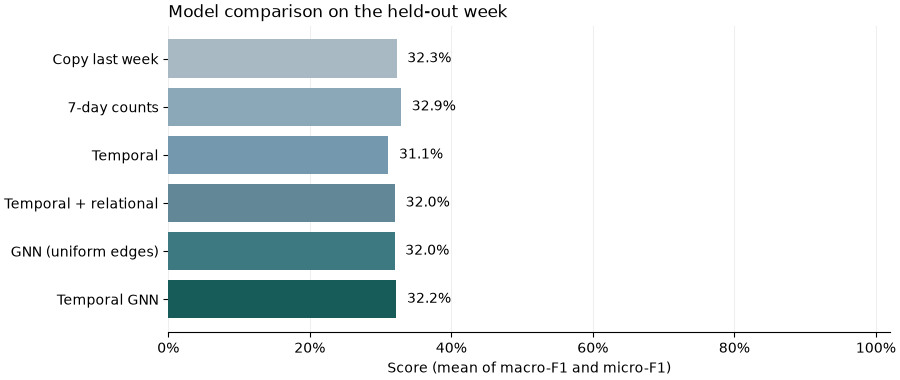

In [13]:
held_out_scores = {
    name: scores(as_submission(predicted), held_out_truth)
    for name, predicted in held_out_predictions.items()
}
metrics = pd.DataFrame({
    name: {key: result[key] for key in ("macro_f1", "micro_f1", "score")}
    for name, result in held_out_scores.items()
}).T
per_activity = pd.DataFrame({name: result["per_event"] for name, result in held_out_scores.items()}).T
display(metrics.style.format("{:.2%}"))
display(per_activity.style.format("{:.2%}"))
observed_events = [event for event in EVENT_COLS if held_out_truth[event].any()]
if 0 < len(observed_events) < len(EVENT_COLS):
    absent = [event for event in EVENT_COLS if event not in observed_events]
    print('Zero observed positives for ' + ', '.join(absent) + '. The course evaluator gives F1 = 1 when predictions and truth are both empty.')
    observed_only = pd.Series({
        name: scores(as_submission(predicted), held_out_truth, events=observed_events)["score"]
        for name, predicted in held_out_predictions.items()
    }, name="Score on activities with held-out positives")
    display(observed_only.to_frame().style.format("{:.2%}"))

graph_delta = 100 * (metrics.loc["GNN (uniform edges)", "score"] - metrics.loc["Temporal + relational", "score"])
decay_delta = 100 * (metrics.loc["Temporal GNN", "score"] - metrics.loc["GNN (uniform edges)", "score"])
print(f"Adding learned graph propagation: {graph_delta:+.2f} percentage points")
print(f"Adding temporal edge weights: {decay_delta:+.2f} percentage points")

fig, ax = plt.subplots(figsize=(9.0, 3.8), layout="constrained")
positions = np.arange(len(metrics))
ax.barh(positions, metrics["score"], color=["#a8b9c4", "#8ba8b9", "#7498ad", "#628897", "#3c7980", "#175c59"])
ax.set_yticks(positions, metrics.index)
ax.invert_yaxis()
ax.set_xlim(0, 1.02)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Score (mean of macro-F1 and micro-F1)")
ax.set_title("Model comparison on the held-out week", loc="left")
for i, score in enumerate(metrics["score"]):
    ax.text(score + 0.015, i, f"{score:.1%}", va="center")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
fig.savefig(RESULTS / "held_out_scores.svg")
plt.show()

metrics.to_csv(RESULTS / "held_out_metrics.csv", index_label="Model")
per_activity.to_csv(RESULTS / "held_out_per_activity.csv", index_label="Model")
folds.to_csv(RESULTS / "historical_windows.csv", index=False)

## Official forecast

Refit the temporal GNN on completed historical folds. Apply the tuned thresholds and check the CSV with the course evaluator.

In [14]:
full_name = "Temporal GNN"
final_gnn = fit_gnn(historical_graphs, feature_weeks, label_weeks, use_decay=True)
test_features = snapshot(archive_end, cohort)
test_graph = graph_at(archive_end)
test_probabilities = predict_gnn(final_gnn, test_graph, test_features).loc[test_users]
test_predictions = as_submission(classify(test_probabilities, thresholds_by_model[full_name]))
print(f"Forecast graph: {test_graph[0]:,} nodes, {len(test_graph[2]):,} relationship instances")

output_path = ROOT / f"output_{STUDENT_ID or 'predictions'}.csv"
temporary = output_path.with_suffix(".csv.part")
test_predictions.to_csv(temporary, index=False)
try:
    checked = subprocess.run([
        sys.executable, str(ROOT / "scripts" / "evaluate.py"),
        "--pred", str(temporary), "--input", str(TEST_INPUT),
    ], check=True, stdout=subprocess.PIPE, text=True)
    temporary.replace(output_path)
finally:
    temporary.unlink(missing_ok=True)
print(checked.stdout.strip())
print(f"Saved {output_path.name}")
print(f"Test users observed during the last 10 days: {test_features.loc[test_users, 'any_activity_days_10d'].gt(0).sum():,}")
display(test_predictions[EVENT_COLS].sum().rename("Predicted positives").to_frame())

GNN loss 0.1564 to 0.1090 over 180 iterations
Forecast graph: 46,458 nodes, 46,358 relationship instances
Format check: no errors (4465 users)
Saved output_315540018.csv
Test users observed during the last 10 days: 1,144


,Predicted positives
open_pr,456
open_issue,292
issue_comment,280
pr_review,298
pr_review_comment,63
push,17


## Schema and pipeline diagrams

Saved results/schema.dot and results/framework.svg.


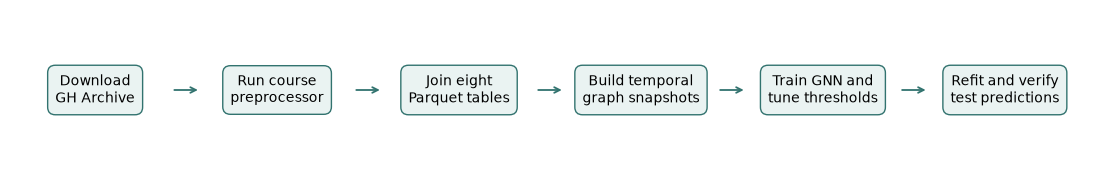

In [15]:
from scripts.schema_diagram import schema_dot

(RESULTS / "schema.dot").write_text(schema_dot(TABLES), encoding="utf-8")

steps = [
    "Download\nGH Archive",
    "Run course\npreprocessor",
    "Join eight\nParquet tables",
    "Build temporal\ngraph snapshots",
    "Train GNN and\ntune thresholds",
    "Refit and verify\ntest predictions",
]
fig, ax = plt.subplots(figsize=(11, 1.8), layout="constrained")
ax.set(xlim=(-0.5, len(steps) - 0.5), ylim=(-0.5, 0.5))
ax.axis("off")
for i, step in enumerate(steps):
    ax.text(i, 0, step, ha="center", va="center", fontsize=10,
            bbox={"boxstyle": "round,pad=0.55", "facecolor": "#eaf3f2", "edgecolor": "#32736f"})
    if i:
        ax.annotate("", (i - 0.42, 0), (i - 0.58, 0),
                    arrowprops={"arrowstyle": "->", "color": "#32736f", "lw": 1.3})
fig.savefig(RESULTS / "framework.svg")
plt.show()
print("Saved results/schema.dot and results/framework.svg.")